# Active Learning: Tasks 1 and 2
Joanne Mesadieu

Executed analysis: LabelSpreading, Digits and Wine. Results and full methods follow the code.

INITIAL LABEL-BUDGET COMPARISON
         experiment  initial_labels  labeled_mean  unlabeled_mean  macro_f1_mean  test_macro_f1_mean  test_macro_f1_std  delta_test_macro_f1_vs_baseline
             Digits               4           4.0          1433.0        0.18213             0.18265            0.03784                         -0.72578
             Digits              40          40.0          1397.0        0.90774             0.90843            0.03559                          0.00000
             Digits             400         400.0          1037.0        0.98000             0.97820            0.00588                          0.06977
               Wine               4           4.0           138.0        0.59400             0.59134            0.17077                         -0.39327
               Wine              40          40.0           102.0        0.94844             0.98461            0.02294                          0.00000
Wine_feasible10fold               1           1.0 

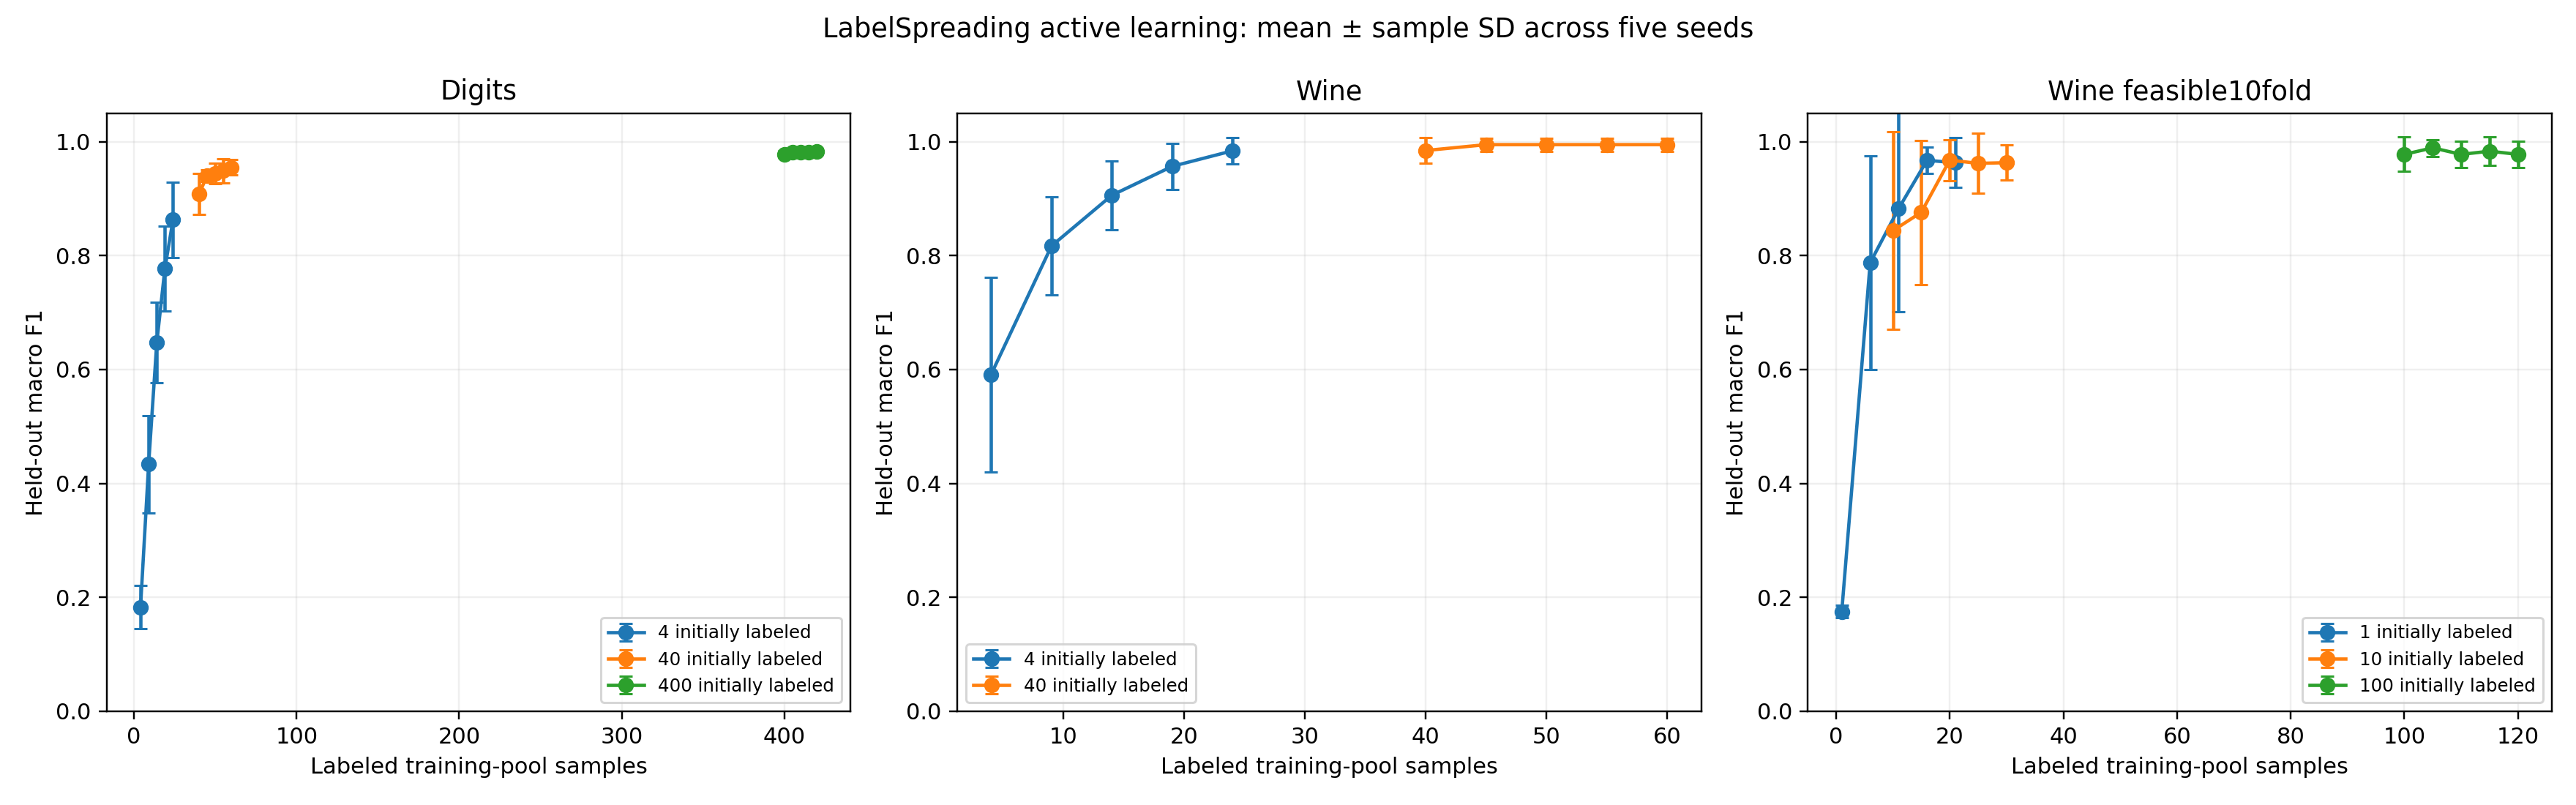

In [1]:
"""Adaptation of supplied Clay Woolam / scikit-learn BSD example.
LabelSpreading active learning: Digits and Wine, reproducible label budgets.
"""
from pathlib import Path
import json, warnings, base64, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from sklearn.datasets import load_digits, load_wine
from sklearn.semi_supervised import LabelSpreading
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
import sklearn
from threadpoolctl import threadpool_limits

OUT=Path('active_learning_results'); OUT.mkdir(exist_ok=True)
SEEDS=[0,1,2,3,4]
rows=[]; reports={}; query_records=[]

def score(y,p,classes):
    return dict(macro_f1=f1_score(y,p,labels=classes,average='macro',zero_division=0),
                weighted_f1=f1_score(y,p,labels=classes,average='weighted',zero_division=0))

def active_learning(X,y,initial,experiment,seed,Xtest=None,ytest=None,rounds=5):
    """Only initial/oracle-queried labels enter fitting. -1 means unlabeled."""
    classes=np.unique(y)
    if initial>len(y):
        rows.append(dict(experiment=experiment,seed=seed,iteration=0,initial_labels=initial,
                         total_pool=len(y),status='infeasible: requested labels exceed pool'))
        return
    unlabeled=np.arange(initial,len(y))
    for iteration in range(rounds):
        if len(unlabeled)==0:
            break
        masked=y.copy(); masked[unlabeled]=-1
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model=LabelSpreading(gamma=.25,max_iter=20)
            model.fit(X,masked)
        pred=model.transduction_[unlabeled]
        metrics=score(y[unlabeled],pred,classes)
        row=dict(experiment=experiment,seed=seed,iteration=iteration,initial_labels=initial,
            labeled=len(y)-len(unlabeled),unlabeled=len(unlabeled),total_pool=len(y),
            represented_classes=len(np.unique(masked[masked!=-1])),n_classes=len(classes),
            macro_f1=metrics['macro_f1'],weighted_f1=metrics['weighted_f1'],
            convergence_warning=any(issubclass(w.category,ConvergenceWarning) for w in caught),
            fit_iterations=int(model.n_iter_),status='ok')
        if Xtest is not None:
            testscore=score(ytest,model.predict(Xtest),classes)
            row.update(test_macro_f1=testscore['macro_f1'],test_weighted_f1=testscore['weighted_f1'],
                       test_samples=len(ytest))
        rows.append(row)
        if seed==0:
            key=f'{experiment}_initial{initial}_iteration{iteration}'
            reports[key]=dict(report=classification_report(y[unlabeled],pred,labels=classes,
                         zero_division=0,output_dict=True),
                         confusion_matrix=confusion_matrix(y[unlabeled],pred,labels=classes).tolist())
        # Do not acquire unused labels after the final evaluated fit.
        if iteration==rounds-1: break
        uncertainty=entropy(model.label_distributions_.T)
        order=np.argsort(uncertainty)[::-1]
        queried=order[np.isin(order,unlabeled)][:min(5,len(unlabeled))]
        for idx in queried:
            query_records.append(dict(experiment=experiment,seed=seed,initial_labels=initial,
                after_iteration=iteration,pool_index=int(idx),oracle_label=int(y[idx])))
        unlabeled=unlabeled[~np.isin(unlabeled,queried)]

def shuffled_pool(data,n,seed):
    indices=np.arange(len(data.target)); np.random.RandomState(seed).shuffle(indices)
    ids=indices[:n]
    return data.data[ids].astype(float),data.target[ids]

def main():
    digits,wine=load_digits(),load_wine()
    # Literal uploaded setup: first 330 shuffled rows, 40 initial labels.
    X,y=shuffled_pool(digits,330,0)
    for budget in [4,40,400]:
        active_learning(X,y,budget,'Digits_original330',0)
    # Literal Wine substitution: uses all 178 rows. The 400-label case is invalid.
    X,y=shuffled_pool(wine,178,0)
    for budget in [4,40,400]:
        active_learning(X,y,budget,'Wine_raw_original_method',0)
    # Main controlled Digits comparison. Same evaluation split for all budgets.
    # Raw pixels preserve original RBF geometry; all 1,797 observations are used.
    # Wine is standardized since raw chemical features have incompatible scales.
    for name,data,budgets,scale in [('Digits',digits,[4,40,400],False),
                                    ('Wine',wine,[4,40,400],True),
                                    ('Wine_feasible10fold',wine,[1,10,100],True)]:
        for seed in SEEDS:
            pool,test=train_test_split(np.arange(len(data.target)),test_size=.2,
                stratify=data.target,random_state=seed)
            # Membership is stratified only to make a representative fixed test set.
            # Label acquisition is random/entropy based, never class-stratified.
            np.random.RandomState(seed).shuffle(pool)
            X=data.data[pool].astype(float); Xt=data.data[test].astype(float)
            if scale:
                scaler=StandardScaler().fit(X); X=scaler.transform(X); Xt=scaler.transform(Xt)
            for budget in budgets:
                active_learning(X,data.target[pool],budget,name,seed,Xt,data.target[test])
    df=pd.DataFrame(rows)
    df.to_csv(OUT/'f1_results_all_runs.csv',index=False,na_rep='N/A')
    pd.DataFrame(query_records).to_csv(OUT/'queried_labels.csv',index=False)
    (OUT/'classification_reports.json').write_text(json.dumps(reports,indent=2),encoding='utf-8')
    valid=df[df.status=='ok'].copy()
    metrics=['labeled','unlabeled','macro_f1','weighted_f1','test_macro_f1','test_weighted_f1']
    agg=valid.groupby(['experiment','initial_labels','iteration'])[metrics].agg(['mean','std'])
    agg.columns=['_'.join(c) for c in agg.columns]; agg=agg.reset_index()
    agg.to_csv(OUT/'f1_summary_mean_std.csv',index=False,na_rep='N/A')
    initial=agg[agg.iteration==0].copy(); initial['delta_test_macro_f1_vs_baseline']=np.nan
    for name in ['Digits','Wine','Wine_feasible10fold']:
        baseline=10 if name=='Wine_feasible10fold' else 40
        t=initial[(initial.experiment==name)&(initial.initial_labels==baseline)]
        value=t.test_macro_f1_mean.iloc[0]
        mask=initial.experiment==name
        initial.loc[mask,'delta_test_macro_f1_vs_baseline']=initial.loc[mask,'test_macro_f1_mean']-value
    initial.to_csv(OUT/'initial_budget_comparison.csv',index=False,na_rep='N/A')
    fig,axes=plt.subplots(1,3,figsize=(16,5))
    for ax,name in zip(axes,['Digits','Wine','Wine_feasible10fold']):
        for budget in sorted(valid[valid.experiment==name].initial_labels.unique()):
            t=agg[(agg.experiment==name)&(agg.initial_labels==budget)]
            ax.errorbar(t.labeled_mean,t.test_macro_f1_mean,yerr=t.test_macro_f1_std,
                        marker='o',capsize=3,label=f'{budget} initially labeled')
        ax.set(title=name.replace('_',' '),xlabel='Labeled training-pool samples',ylabel='Held-out macro F1',ylim=(0,1.05))
        ax.legend(fontsize=8); ax.grid(alpha=.2)
    fig.suptitle('LabelSpreading active learning: mean ± sample SD across five seeds')
    fig.tight_layout(); fig.savefig(OUT/'f1_label_budget_comparison.png',dpi=220); plt.close(fig)
    version=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__)
    (OUT/'environment.json').write_text(json.dumps(version,indent=2),encoding='utf-8')
    selected=initial[initial.experiment.isin(['Digits','Wine','Wine_feasible10fold'])]
    displaycols=['experiment','initial_labels','labeled_mean','unlabeled_mean',
                 'macro_f1_mean','test_macro_f1_mean','test_macro_f1_std','delta_test_macro_f1_vs_baseline']
    summary=selected[displaycols].round(5).to_string(index=False)
    print('INITIAL LABEL-BUDGET COMPARISON\n'+summary,flush=True)
    infeasible=df[df.status!='ok'][['experiment','seed','initial_labels','total_pool','status']]
    print('\nINFEASIBLE SETTINGS\n'+infeasible.to_string(index=False),flush=True)
    report=['# Active Learning: Digits and Wine','Joanne Mesadieu',
      '## Source and corrections',
      'Based on the supplied active_learning(1).ipynb, a Clay Woolam / scikit-learn BSD example. Its executable code uses LabelSpreading, 40 initial labels, 330 Digits observations, gamma=0.25, max_iter=20 and five fits. The introduction says 10 labels and the plot annotations also assume 10; the actual code starts at 40. This analysis follows the executable value. np.in1d was replaced by np.isin for current NumPy compatibility. True class IDs are never multiplied by ten: the NUMBER of labeled observations changes.',
      '## Task 1: label counts and F1 changes',
      'The original 330-sample Digits pool was rerun with 4 and 40 initial labels; 400 is explicitly infeasible. To compare 4, 40 and 400 fairly, the main experiment uses all Digits observations and holds out 20% for testing (1,437 pool, 360 test). Every budget shares the same split and nested random initial label sets within each seed. Seeds: 0,1,2,3,4. Each round queries the five highest-entropy currently unlabeled samples, obtains their true labels from a simulated oracle, then refits. Reported counts are the counts at model fitting, not the count after acquisition. At round zero the ratios are exact; after four acquisitions the counts are 24,60,420.',
      '```text\n'+summary+'\n```',
      'macro_f1_mean is transductive F1 on the remaining unlabeled training-pool observations. test_macro_f1_mean is inductive F1 on the fixed held-out test observations, which are never supplied to graph fitting or label queries. The held-out score is the stronger basis for comparing budgets because the transductive evaluation set shrinks and changes as difficult points are acquired. Macro F1 includes every known dataset class with zero_division=0, including classes absent from the seed labels. Weighted F1 is also saved. A sample SD is reported across seeds; an SD for a single original reproduction run is N/A.',
      '## Task 2: Wine dataset',
      'First, the original algorithm was rerun on all 178 raw Wine rows with 4 and 40 labels. This literal substitution preserves gamma=0.25 and is saved separately from the controlled Wine analysis. Chemical features use different units and scales, so the controlled analysis standardizes using training-pool features only (142 pool, 36 held-out test). The direct 400-label request remains infeasible; it is not silently capped or duplicated. A supplemental 1/10/100 initial-label experiment supplies a feasible exact tenfold comparison with the same Wine split and scaling. One initial label cannot represent all three classes; its poor initial class coverage is intentional and recorded.',
      '## Interpreting the results']
    for name in ['Digits','Wine','Wine_feasible10fold']:
        t=selected[selected.experiment==name].sort_values('initial_labels')
        report.append(name+': '+ '; '.join(f'{int(r.initial_labels)} labels: held-out macro F1 {r.test_macro_f1_mean:.4f} ± {r.test_macro_f1_std:.4f}' for _,r in t.iterrows())+'.')
        low=t.iloc[0]; high=t.iloc[-1]; delta=high.test_macro_f1_mean-low.test_macro_f1_mean
        report.append(f'Change from the lowest to highest feasible initial budget: {delta:+.4f} F1 ({100*delta:+.2f} percentage points). More labels may improve coverage and predictions, but changes need not be monotonic for each seed or acquisition round.')
    warncount=int(valid.convergence_warning.sum())
    report += ['## Limitations',
      f'{warncount} fitted models emitted convergence warnings at the original max_iter=20; these fits are flagged in the results instead of being silently altered. Graph quality depends on scaling and gamma. Very few labels can omit classes; results from one random seed are unreliable. The experiments use a simulated oracle, not human annotation. Active acquisition can change the difficulty of the remaining unlabeled subset. Five seeds describe variability but do not establish a universal performance guarantee. Wine raw versus standardized results change geometry as well as scale and must be identified separately.',
      '## Files','f1_results_all_runs.csv contains every fit and explicit infeasible settings. f1_summary_mean_std.csv contains per-round aggregates. initial_budget_comparison.csv contains the primary factor-of-ten comparison and change relative to baseline. classification_reports.json contains seed-zero reports and confusion matrices. queried_labels.csv records oracle queries. f1_label_budget_comparison.png visualizes held-out learning curves.',
      '## Reproduce','Install numpy, pandas, scipy, scikit-learn, matplotlib and threadpoolctl. Run active_learning_analysis.py or all cells in Active_Learning_Completed.ipynb. No external dataset download is required.',
      '## Attribution','Original example: Clay Woolam, BSD license; scikit-learn LabelSpreading active-learning demonstration. Adaptation adds budget comparisons, Wine, held-out evaluation, repeat seeds, result exports and corrected label-count annotations.']
    reporttext='\n\n'.join(report)
    (OUT/'REPORT.md').write_text(reporttext,encoding='utf-8')
    sourcepath=Path('active_learning_analysis.py')
    if sourcepath.exists():
        source=sourcepath.read_text(encoding='utf-8')
        nb=dict(nbformat=4,nbformat_minor=5,metadata=dict(kernelspec=dict(name='python3',display_name='Python 3',language='python')),cells=[
          dict(cell_type='markdown',id='intro',metadata={},source=['# Active Learning: Tasks 1 and 2\n','Joanne Mesadieu\n\n','Executed analysis: LabelSpreading, Digits and Wine. Results and full methods follow the code.']),
          dict(cell_type='code',id='analysis',metadata={},execution_count=1,source=source.splitlines(keepends=True),outputs=[dict(output_type='stream',name='stdout',text=['INITIAL LABEL-BUDGET COMPARISON\n'+summary+'\n']),dict(output_type='display_data',metadata={},data={'image/png':base64.b64encode((OUT/'f1_label_budget_comparison.png').read_bytes()).decode(),'text/plain':['<Figure: F1 learning curves>']})]),
          dict(cell_type='markdown',id='report',metadata={},source=reporttext.splitlines(keepends=True))])
        (OUT/'Active_Learning_Completed.ipynb').write_text(json.dumps(nb,indent=2),encoding='utf-8')
        (OUT/'active_learning_analysis.py').write_text(source,encoding='utf-8')
    (OUT/'requirements.txt').write_text('numpy\npandas\nscipy\nscikit-learn\nmatplotlib\nthreadpoolctl\n',encoding='utf-8')
    with zipfile.ZipFile('Active_Learning_Completed.zip','w',zipfile.ZIP_DEFLATED) as archive:
        for p in OUT.iterdir():
            if p.is_file(): archive.write(p,p.name)
    print('\nSaved Active_Learning_Completed.zip',flush=True)

if __name__=='__main__':
    with threadpool_limits(limits=1): main()


# Active Learning: Digits and Wine

Joanne Mesadieu

## Source and corrections

Based on the supplied active_learning(1).ipynb, a Clay Woolam / scikit-learn BSD example. Its executable code uses LabelSpreading, 40 initial labels, 330 Digits observations, gamma=0.25, max_iter=20 and five fits. The introduction says 10 labels and the plot annotations also assume 10; the actual code starts at 40. This analysis follows the executable value. np.in1d was replaced by np.isin for current NumPy compatibility. True class IDs are never multiplied by ten: the NUMBER of labeled observations changes.

## Task 1: label counts and F1 changes

The original 330-sample Digits pool was rerun with 4 and 40 initial labels; 400 is explicitly infeasible. To compare 4, 40 and 400 fairly, the main experiment uses all Digits observations and holds out 20% for testing (1,437 pool, 360 test). Every budget shares the same split and nested random initial label sets within each seed. Seeds: 0,1,2,3,4. Each round queries the five highest-entropy currently unlabeled samples, obtains their true labels from a simulated oracle, then refits. Reported counts are the counts at model fitting, not the count after acquisition. At round zero the ratios are exact; after four acquisitions the counts are 24,60,420.

```text
         experiment  initial_labels  labeled_mean  unlabeled_mean  macro_f1_mean  test_macro_f1_mean  test_macro_f1_std  delta_test_macro_f1_vs_baseline
             Digits               4           4.0          1433.0        0.18213             0.18265            0.03784                         -0.72578
             Digits              40          40.0          1397.0        0.90774             0.90843            0.03559                          0.00000
             Digits             400         400.0          1037.0        0.98000             0.97820            0.00588                          0.06977
               Wine               4           4.0           138.0        0.59400             0.59134            0.17077                         -0.39327
               Wine              40          40.0           102.0        0.94844             0.98461            0.02294                          0.00000
Wine_feasible10fold               1           1.0           141.0        0.17420             0.17467            0.01095                         -0.66914
Wine_feasible10fold              10          10.0           132.0        0.80066             0.84381            0.17319                          0.00000
Wine_feasible10fold             100         100.0            42.0        0.95200             0.97784            0.03034                          0.13403
```

macro_f1_mean is transductive F1 on the remaining unlabeled training-pool observations. test_macro_f1_mean is inductive F1 on the fixed held-out test observations, which are never supplied to graph fitting or label queries. The held-out score is the stronger basis for comparing budgets because the transductive evaluation set shrinks and changes as difficult points are acquired. Macro F1 includes every known dataset class with zero_division=0, including classes absent from the seed labels. Weighted F1 is also saved. A sample SD is reported across seeds; an SD for a single original reproduction run is N/A.

## Task 2: Wine dataset

First, the original algorithm was rerun on all 178 raw Wine rows with 4 and 40 labels. This literal substitution preserves gamma=0.25 and is saved separately from the controlled Wine analysis. Chemical features use different units and scales, so the controlled analysis standardizes using training-pool features only (142 pool, 36 held-out test). The direct 400-label request remains infeasible; it is not silently capped or duplicated. A supplemental 1/10/100 initial-label experiment supplies a feasible exact tenfold comparison with the same Wine split and scaling. One initial label cannot represent all three classes; its poor initial class coverage is intentional and recorded.

## Interpreting the results

Digits: 4 labels: held-out macro F1 0.1826 ± 0.0378; 40 labels: held-out macro F1 0.9084 ± 0.0356; 400 labels: held-out macro F1 0.9782 ± 0.0059.

Change from the lowest to highest feasible initial budget: +0.7955 F1 (+79.55 percentage points). More labels may improve coverage and predictions, but changes need not be monotonic for each seed or acquisition round.

Wine: 4 labels: held-out macro F1 0.5913 ± 0.1708; 40 labels: held-out macro F1 0.9846 ± 0.0229.

Change from the lowest to highest feasible initial budget: +0.3933 F1 (+39.33 percentage points). More labels may improve coverage and predictions, but changes need not be monotonic for each seed or acquisition round.

Wine_feasible10fold: 1 labels: held-out macro F1 0.1747 ± 0.0110; 10 labels: held-out macro F1 0.8438 ± 0.1732; 100 labels: held-out macro F1 0.9778 ± 0.0303.

Change from the lowest to highest feasible initial budget: +0.8032 F1 (+80.32 percentage points). More labels may improve coverage and predictions, but changes need not be monotonic for each seed or acquisition round.

## Limitations

0 fitted models emitted convergence warnings at the original max_iter=20; these fits are flagged in the results instead of being silently altered. Graph quality depends on scaling and gamma. Very few labels can omit classes; results from one random seed are unreliable. The experiments use a simulated oracle, not human annotation. Active acquisition can change the difficulty of the remaining unlabeled subset. Five seeds describe variability but do not establish a universal performance guarantee. Wine raw versus standardized results change geometry as well as scale and must be identified separately.

## Files

f1_results_all_runs.csv contains every fit and explicit infeasible settings. f1_summary_mean_std.csv contains per-round aggregates. initial_budget_comparison.csv contains the primary factor-of-ten comparison and change relative to baseline. classification_reports.json contains seed-zero reports and confusion matrices. queried_labels.csv records oracle queries. f1_label_budget_comparison.png visualizes held-out learning curves.

## Reproduce

Install numpy, pandas, scipy, scikit-learn, matplotlib and threadpoolctl. Run active_learning_analysis.py or all cells in Active_Learning_Completed.ipynb. No external dataset download is required.

## Attribution

Original example: Clay Woolam, BSD license; scikit-learn LabelSpreading active-learning demonstration. Adaptation adds budget comparisons, Wine, held-out evaluation, repeat seeds, result exports and corrected label-count annotations.